## Imports

In [1]:
import os
import copy
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## Load Data

In [3]:
possible_paths = [
    Path("Data2/original"),
    Path("../Data2/original"),
    Path("original"),
]

for path in possible_paths:
    if path.exists():
        print("Dataset found at:", path.resolve())
        print("Contents:", os.listdir(path))
        break
else:
    print("Dataset not found in the common locations.")
    print("Current working directory:", Path.cwd())

Dataset found at: C:\Users\sohail\PycharmProjects\PythonProject\Data2\original
Contents: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [4]:
DATA_DIR = Path("Data2/original")

class_folders = sorted([
    folder for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Number of classes:", len(class_folders))
print("\nClasses and image counts:")

for folder in class_folders:
    image_count = len(list(folder.glob("*.jpg")))
    print(f"{folder.name}: {image_count}")

print("\nTotal images:", sum(
    len(list(folder.glob("*.jpg")))
    for folder in class_folders
))

Number of classes: 10

Classes and image counts:
battery: 1701
biological: 1684
cardboard: 2302
clothes: 7217
glass: 3747
metal: 1699
paper: 2386
plastic: 2462
shoes: 3426
trash: 1149

Total images: 27773


## Split Data

In [5]:
from sklearn.model_selection import train_test_split
import pandas as pd

In [6]:
DATASET_PATH = Path("Data2/original")

classes = sorted([
    folder.name
    for folder in DATASET_PATH.iterdir()
    if folder.is_dir()
])

In [7]:
data = []

for category in classes:
    for file in (DATASET_PATH / category).iterdir():
        if file.is_file() and file.suffix.lower() == ".jpg":
            data.append({
                "image_path": str(file),
                "label": category
            })

df = pd.DataFrame(data)

In [8]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

In [9]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(df))

print("\nClasses:", classes)

Training images: 19441
Validation images: 4166
Testing images: 4166
Total images: 27773

Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


## Create dataset to feed to ResNet50

In [10]:
print("\nClasses:", classes)
weights = models.ResNet50_Weights.DEFAULT

mean = weights.transforms().mean
std = weights.transforms().std


Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [11]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("ResNet50 transformations created!")
print("Input size: 224 x 224")
print("Normalization mean:", mean)
print("Normalization std:", std)

ResNet50 transformations created!
Input size: 224 x 224
Normalization mean: [0.485, 0.456, 0.406]
Normalization std: [0.229, 0.224, 0.225]


In [12]:
class WasteDataset(Dataset):

    def __init__(self, dataframe, class_to_idx, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.loc[index, "image_path"]
        label = self.dataframe.loc[index, "label"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = self.class_to_idx[label]

        return image, label

In [13]:
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

train_dataset = WasteDataset(train_df, class_to_idx, train_transform)
val_dataset = WasteDataset(val_df, class_to_idx, eval_transform)
test_dataset = WasteDataset(test_df, class_to_idx, eval_transform)

print("Datasets created successfully.")
print("Number of classes:", len(class_to_idx))

Datasets created successfully.
Number of classes: 10


In [14]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [15]:
print("DataLoaders created successfully.")
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Data type:", images.dtype)
print("Device:", device)

print("\nClass mapping:")
print(class_to_idx)

DataLoaders created successfully.
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Data type: torch.float32
Device: cuda

Class mapping:
{'battery': 0, 'biological': 1, 'cardboard': 2, 'clothes': 3, 'glass': 4, 'metal': 5, 'paper': 6, 'plastic': 7, 'shoes': 8, 'trash': 9}


## Get pre-trained resnet50 ready

In [16]:
weights = models.ResNet50_Weights.DEFAULT

mean = weights.transforms().mean
std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("ResNet50 transformations created!")
print("Input size: 224 x 224")
print("Normalization mean:", mean)
print("Normalization std:", std)

ResNet50 transformations created!
Input size: 224 x 224
Normalization mean: [0.485, 0.456, 0.406]
Normalization std: [0.229, 0.224, 0.225]


In [17]:
resnet_model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

print("Pretrained ResNet50 loaded successfully!")

Pretrained ResNet50 loaded successfully!


In [18]:
for param in resnet_model.parameters():
    param.requires_grad = False

in_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    in_features,
    len(classes)
)

resnet_model = resnet_model.to(device)

print(resnet_model.fc)

Linear(in_features=2048, out_features=10, bias=True)


In [19]:
total_params = sum(
    p.numel() for p in resnet_model.parameters()
)

trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 23,528,522
Trainable parameters: 20,490
Frozen parameters: 23,508,032
Trainable percentage: 0.09%


In [20]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [21]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    # Keep the frozen backbone in evaluation mode.
    # This prevents BatchNorm running statistics from changing.
    model.eval()
    model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [22]:
def evaluate_model(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = np.mean(
        np.array(all_predictions) == np.array(all_labels)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return epoch_loss, accuracy, macro_f1

## Train the model

In [23]:
EPOCHS = 20

best_val_f1 = -1
best_epoch = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        resnet_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_f1 = evaluate_model(
        resnet_model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc*100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc*100:.2f}% "
        f"| Val Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": resnet_model.state_dict(),
                "class_to_idx": class_to_idx,
                "best_epoch": best_epoch,
                "val_f1": best_val_f1
            },
            "best_waste_resnet50.pth"
        )

        print("  -> Best model saved!")

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print(f"Best validation macro F1: {best_val_f1:.4f}")

Epoch [1/20] | Train Loss: 0.5300 | Train Acc: 85.35% | Val Loss: 0.2176 | Val Acc: 94.00% | Val Macro F1: 0.9264
  -> Best model saved!
Epoch [2/20] | Train Loss: 0.2935 | Train Acc: 90.77% | Val Loss: 0.1702 | Val Acc: 95.30% | Val Macro F1: 0.9425
  -> Best model saved!
Epoch [3/20] | Train Loss: 0.2531 | Train Acc: 92.03% | Val Loss: 0.1496 | Val Acc: 95.63% | Val Macro F1: 0.9462
  -> Best model saved!
Epoch [4/20] | Train Loss: 0.2367 | Train Acc: 92.43% | Val Loss: 0.1372 | Val Acc: 95.87% | Val Macro F1: 0.9493
  -> Best model saved!
Epoch [5/20] | Train Loss: 0.2243 | Train Acc: 92.73% | Val Loss: 0.1296 | Val Acc: 96.09% | Val Macro F1: 0.9517
  -> Best model saved!
Epoch [6/20] | Train Loss: 0.2137 | Train Acc: 93.07% | Val Loss: 0.1262 | Val Acc: 95.94% | Val Macro F1: 0.9498
Epoch [7/20] | Train Loss: 0.2013 | Train Acc: 93.43% | Val Loss: 0.1218 | Val Acc: 96.42% | Val Macro F1: 0.9565
  -> Best model saved!
Epoch [8/20] | Train Loss: 0.1945 | Train Acc: 93.65% | Val Loss

## Analyze training

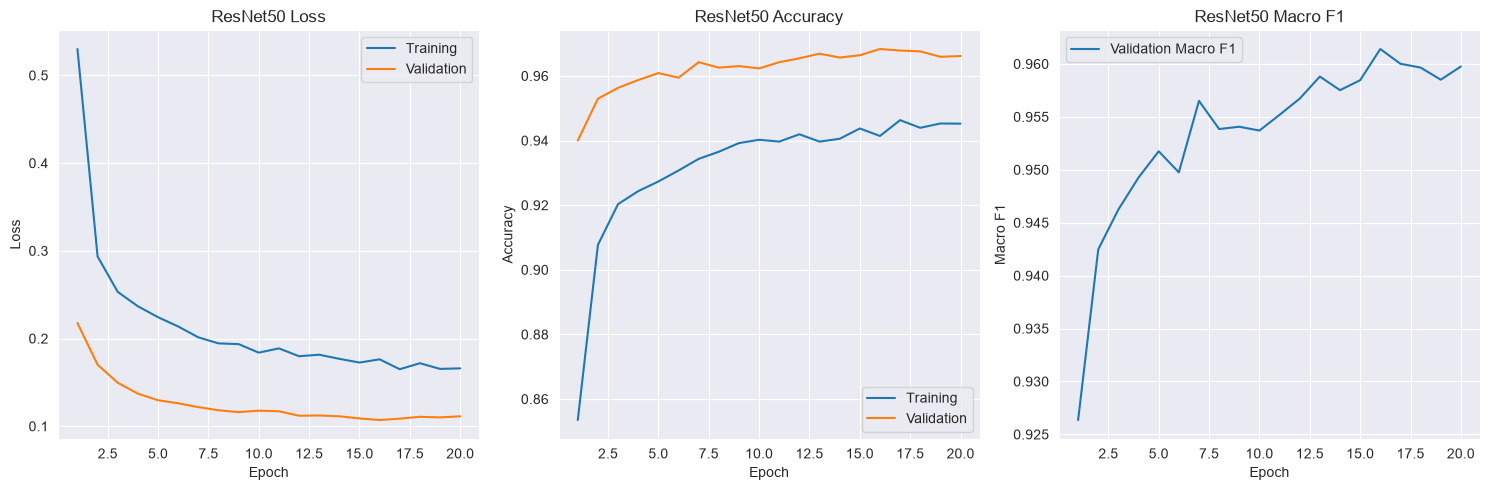

In [24]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(15, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(epochs_range, history["train_loss"], label="Training")
plt.plot(epochs_range, history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Loss")
plt.legend()

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(epochs_range, history["train_acc"], label="Training")
plt.plot(epochs_range, history["val_acc"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()

# Macro F1
plt.subplot(1, 3, 3)
plt.plot(epochs_range, history["val_f1"], label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("ResNet50 Macro F1")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
checkpoint = torch.load(
    "best_waste_resnet50.pth",
    map_location=device,
    weights_only=False
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model.eval()

print("Best ResNet50 checkpoint loaded!")
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation F1:", checkpoint["val_f1"])

Best ResNet50 checkpoint loaded!
Best epoch: 16
Best validation F1: 0.9614043391693203


In [26]:
all_predictions = []
all_labels = []

resnet_model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = resnet_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Total validation predictions:", len(all_predictions))

Total validation predictions: 4166


In [27]:
test_accuracy = accuracy_score(all_labels, all_predictions)

macro_precision = precision_score(
    all_labels, all_predictions, average="macro"
)

macro_recall = recall_score(
    all_labels, all_predictions, average="macro"
)

macro_f1 = f1_score(
    all_labels, all_predictions, average="macro"
)

weighted_precision = precision_score(
    all_labels, all_predictions, average="weighted"
)

weighted_recall = recall_score(
    all_labels, all_predictions, average="weighted"
)

weighted_f1 = f1_score(
    all_labels, all_predictions, average="weighted"
)

print("=" * 55)
print("RESNET50 — VALIDATION RESULTS")
print("=" * 55)

print(f"Accuracy:           {test_accuracy * 100:.2f}%")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1-score:     {macro_f1:.4f}")

print(f"\nWeighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-score:  {weighted_f1:.4f}")

class_labels = [
    idx_to_class[i] for i in range(len(idx_to_class))
]

print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_labels))),
    target_names=class_labels,
    digits=4
))

RESNET50 — VALIDATION RESULTS
Accuracy:           96.83%
Macro Precision:    0.9624
Macro Recall:       0.9605
Macro F1-score:     0.9614

Weighted Precision: 0.9683
Weighted Recall:    0.9683
Weighted F1-score:  0.9682

Classification Report:

              precision    recall  f1-score   support

     battery     0.9882    0.9882    0.9882       255
  biological     0.9882    1.0000    0.9941       252
   cardboard     0.9565    0.9565    0.9565       345
     clothes     0.9944    0.9926    0.9935      1083
       glass     0.9459    0.9644    0.9551       562
       metal     0.9467    0.9059    0.9259       255
       paper     0.9446    0.9525    0.9485       358
     plastic     0.9396    0.9243    0.9319       370
       shoes     0.9845    0.9903    0.9874       514
       trash     0.9357    0.9302    0.9329       172

    accuracy                         0.9683      4166
   macro avg     0.9624    0.9605    0.9614      4166
weighted avg     0.9683    0.9683    0.9682      41

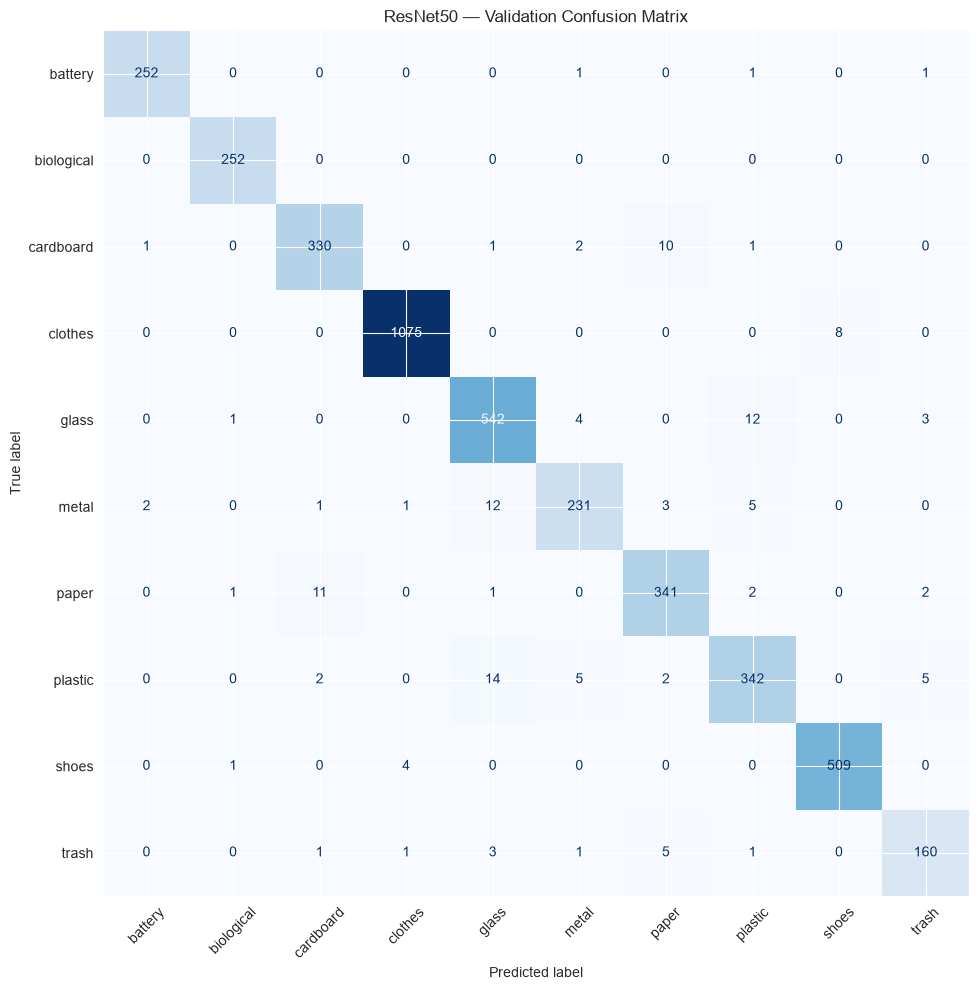

In [28]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_labels)))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("ResNet50 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
checkpoint = torch.load(
    "best_waste_resnet50.pth",
    map_location=device,
    weights_only=False
)

fine_resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Replace classifier
fine_resnet.fc = nn.Linear(
    fine_resnet.fc.in_features,
    len(classes)
)

# Load trained classifier and pretrained backbone
fine_resnet.load_state_dict(checkpoint["model_state_dict"])

print("Checkpoint loaded successfully!")
print("Starting checkpoint epoch:", checkpoint["best_epoch"])
print("Previous validation macro F1:", checkpoint["val_f1"])

Checkpoint loaded successfully!
Starting checkpoint epoch: 16
Previous validation macro F1: 0.9614043391693203


In [30]:
# Freeze all parameters
for param in fine_resnet.parameters():
    param.requires_grad = False

# Unfreeze the final residual block
for param in fine_resnet.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in fine_resnet.fc.parameters():
    param.requires_grad = True

fine_resnet = fine_resnet.to(device)

# Inspect trainable parameters
total_params = sum(
    p.numel() for p in fine_resnet.parameters()
)

trainable_params = sum(
    p.numel() for p in fine_resnet.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.2f}%")

Total parameters: 23,528,522
Trainable parameters: 14,985,226
Frozen parameters: 8,543,296
Trainable percentage: 63.69%


In [31]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam([
    {
        "params": fine_resnet.layer4.parameters(),
        "lr": 0.0001
    },
    {
        "params": fine_resnet.fc.parameters(),
        "lr": 0.0005
    }
])

print("Fine-tuning optimizer configured!")

Fine-tuning optimizer configured!


In [32]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    # Keep frozen layers in evaluation mode
    model.eval()

    # Enable training mode for unfrozen layers
    model.layer4.train()
    model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [33]:
EPOCHS = 30
PATIENCE = 5

best_val_f1 = -1
best_epoch = 0
patience_counter = 0

fine_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        fine_resnet,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_f1 = evaluate_model(
        fine_resnet,
        val_loader,
        criterion,
        device
    )

    fine_history["train_loss"].append(train_loss)
    fine_history["train_acc"].append(train_acc)
    fine_history["val_loss"].append(val_loss)
    fine_history["val_acc"].append(val_acc)
    fine_history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc*100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc*100:.2f}% "
        f"| Val Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            {
                "model_state_dict": fine_resnet.state_dict(),
                "class_to_idx": class_to_idx,
                "best_epoch": best_epoch,
                "val_f1": best_val_f1
            },
            "best_waste_resnet50_finetuned.pth"
        )

        print("  -> Best model saved!")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nFine-tuning completed!")
print("Best epoch:", best_epoch)
print(f"Best validation macro F1: {best_val_f1:.4f}")

Epoch [1/30] | Train Loss: 0.1997 | Train Acc: 93.47% | Val Loss: 0.0913 | Val Acc: 97.19% | Val Macro F1: 0.9648
  -> Best model saved!
Epoch [2/30] | Train Loss: 0.1440 | Train Acc: 95.41% | Val Loss: 0.0821 | Val Acc: 97.74% | Val Macro F1: 0.9720
  -> Best model saved!
Epoch [3/30] | Train Loss: 0.1197 | Train Acc: 96.05% | Val Loss: 0.0880 | Val Acc: 97.55% | Val Macro F1: 0.9690
Epoch [4/30] | Train Loss: 0.1049 | Train Acc: 96.63% | Val Loss: 0.0749 | Val Acc: 97.74% | Val Macro F1: 0.9723
  -> Best model saved!
Epoch [5/30] | Train Loss: 0.0880 | Train Acc: 97.02% | Val Loss: 0.0822 | Val Acc: 98.06% | Val Macro F1: 0.9757
  -> Best model saved!
Epoch [6/30] | Train Loss: 0.0798 | Train Acc: 97.40% | Val Loss: 0.0783 | Val Acc: 97.89% | Val Macro F1: 0.9743
Epoch [7/30] | Train Loss: 0.0739 | Train Acc: 97.59% | Val Loss: 0.0820 | Val Acc: 98.22% | Val Macro F1: 0.9779
  -> Best model saved!
Epoch [8/30] | Train Loss: 0.0770 | Train Acc: 97.47% | Val Loss: 0.0814 | Val Acc: 98.

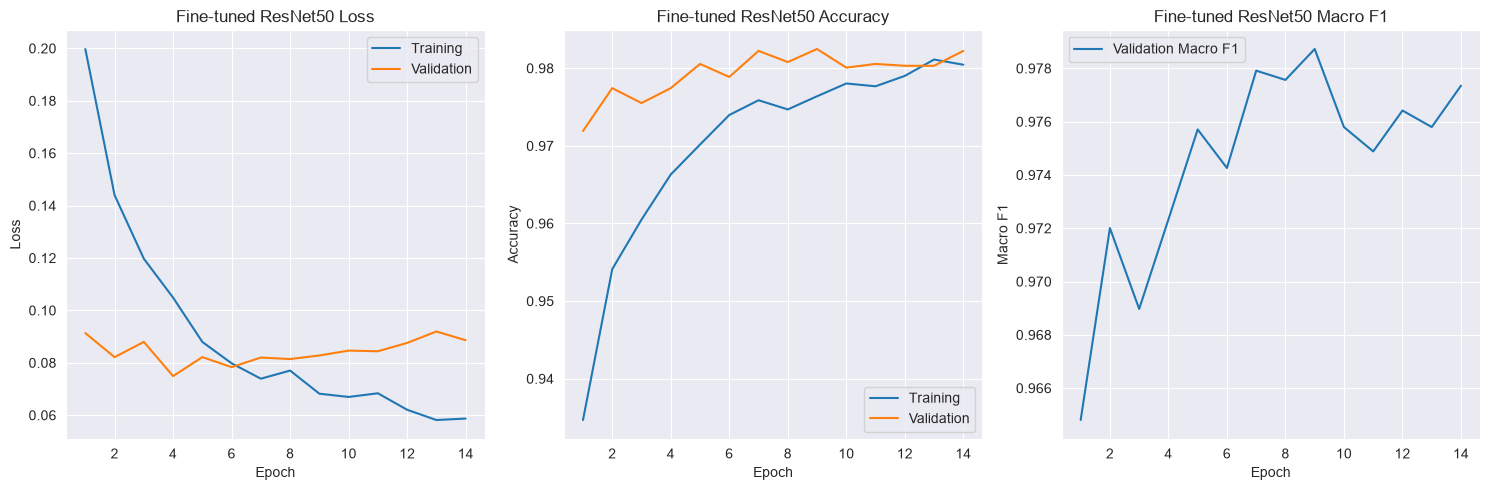

In [34]:
epochs_range = range(1, len(fine_history["train_loss"]) + 1)

plt.figure(figsize=(15, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(epochs_range, fine_history["train_loss"], label="Training")
plt.plot(epochs_range, fine_history["val_loss"], label="Validation")
plt.title("Fine-tuned ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(epochs_range, fine_history["train_acc"], label="Training")
plt.plot(epochs_range, fine_history["val_acc"], label="Validation")
plt.title("Fine-tuned ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Macro F1
plt.subplot(1, 3, 3)
plt.plot(epochs_range, fine_history["val_f1"], label="Validation Macro F1")
plt.title("Fine-tuned ResNet50 Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()

plt.tight_layout()
plt.show()

In [35]:
plt.show()
checkpoint = torch.load(
    "best_waste_resnet50_finetuned.pth",
    map_location=device,
    weights_only=False
)

fine_resnet.load_state_dict(checkpoint["model_state_dict"])
fine_resnet.eval()

print("Best checkpoint loaded!")
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation F1:", checkpoint["val_f1"])

Best checkpoint loaded!
Best epoch: 9
Best validation F1: 0.9787263149394485


In [36]:
all_predictions = []
all_labels = []

fine_resnet.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = fine_resnet(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Total predictions:", len(all_predictions))

Total predictions: 4166


In [37]:
class_labels = [
    idx_to_class[i]
    for i in range(len(idx_to_class))
]

print("Validation Accuracy:",
      f"{accuracy_score(all_labels, all_predictions)*100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_labels))),
    target_names=class_labels,
    digits=4
))

Validation Accuracy: 98.25%

Classification Report:

              precision    recall  f1-score   support

     battery     0.9921    0.9882    0.9902       255
  biological     0.9960    0.9841    0.9900       252
   cardboard     0.9662    0.9942    0.9800       345
     clothes     0.9935    0.9917    0.9926      1083
       glass     0.9840    0.9840    0.9840       562
       metal     0.9685    0.9647    0.9666       255
       paper     0.9884    0.9553    0.9716       358
     plastic     0.9704    0.9757    0.9730       370
       shoes     0.9807    0.9903    0.9855       514
       trash     0.9483    0.9593    0.9538       172

    accuracy                         0.9825      4166
   macro avg     0.9788    0.9788    0.9787      4166
weighted avg     0.9826    0.9825    0.9825      4166



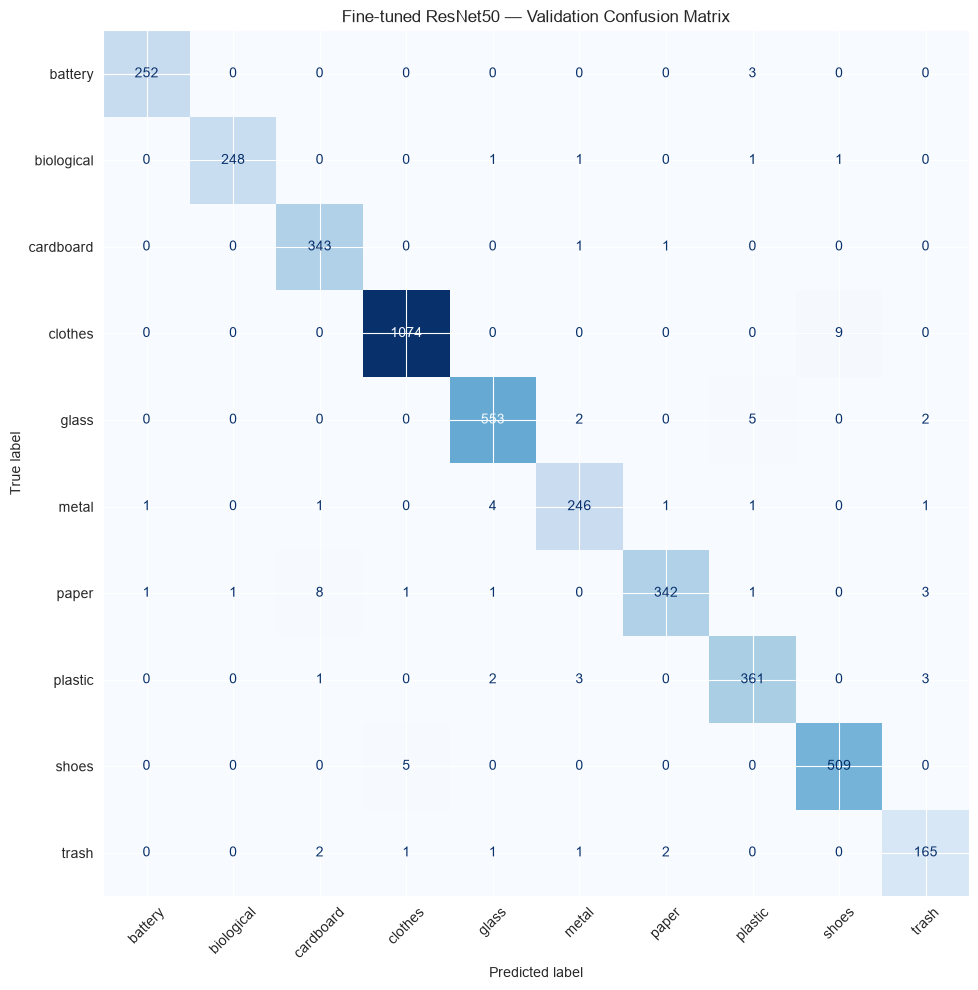

In [38]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_labels)))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Fine-tuned ResNet50 — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [39]:
checkpoint = torch.load(
    "best_waste_resnet50_finetuned.pth",
    map_location=device,
    weights_only=False
)

fine_resnet.load_state_dict(checkpoint["model_state_dict"])
fine_resnet.eval()

print("Best ResNet50 checkpoint loaded!")
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation F1:", checkpoint["val_f1"])

Best ResNet50 checkpoint loaded!
Best epoch: 9
Best validation F1: 0.9787263149394485


In [40]:
all_test_predictions = []
all_test_labels = []

fine_resnet.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = fine_resnet(images)
        predictions = outputs.argmax(dim=1)

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_labels.extend(
            labels.numpy()
        )

print("Total test predictions:", len(all_test_predictions))

Total test predictions: 4166


In [41]:
test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

print("=" * 55)
print("RESNET50 — TEST RESULTS")
print("=" * 55)

print(f"Accuracy: {test_accuracy * 100:.2f}%")

print(f"Macro Precision: {precision_score(all_test_labels, all_test_predictions, average='macro'):.4f}")
print(f"Macro Recall:    {recall_score(all_test_labels, all_test_predictions, average='macro'):.4f}")
print(f"Macro F1:        {f1_score(all_test_labels, all_test_predictions, average='macro'):.4f}")

print("\nClassification Report:\n")

print(classification_report(
    all_test_labels,
    all_test_predictions,
    labels=list(range(len(class_labels))),
    target_names=class_labels,
    digits=4
))

RESNET50 — TEST RESULTS
Accuracy: 98.15%
Macro Precision: 0.9749
Macro Recall:    0.9773
Macro F1:        0.9760

Classification Report:

              precision    recall  f1-score   support

     battery     0.9881    0.9804    0.9843       255
  biological     0.9880    0.9802    0.9841       253
   cardboard     0.9688    0.9884    0.9785       345
     clothes     0.9963    0.9963    0.9963      1082
       glass     0.9874    0.9769    0.9821       562
       metal     0.9647    0.9647    0.9647       255
       paper     0.9828    0.9553    0.9688       358
     plastic     0.9571    0.9675    0.9623       369
       shoes     0.9922    0.9922    0.9922       514
       trash     0.9231    0.9711    0.9465       173

    accuracy                         0.9815      4166
   macro avg     0.9749    0.9773    0.9760      4166
weighted avg     0.9817    0.9815    0.9816      4166



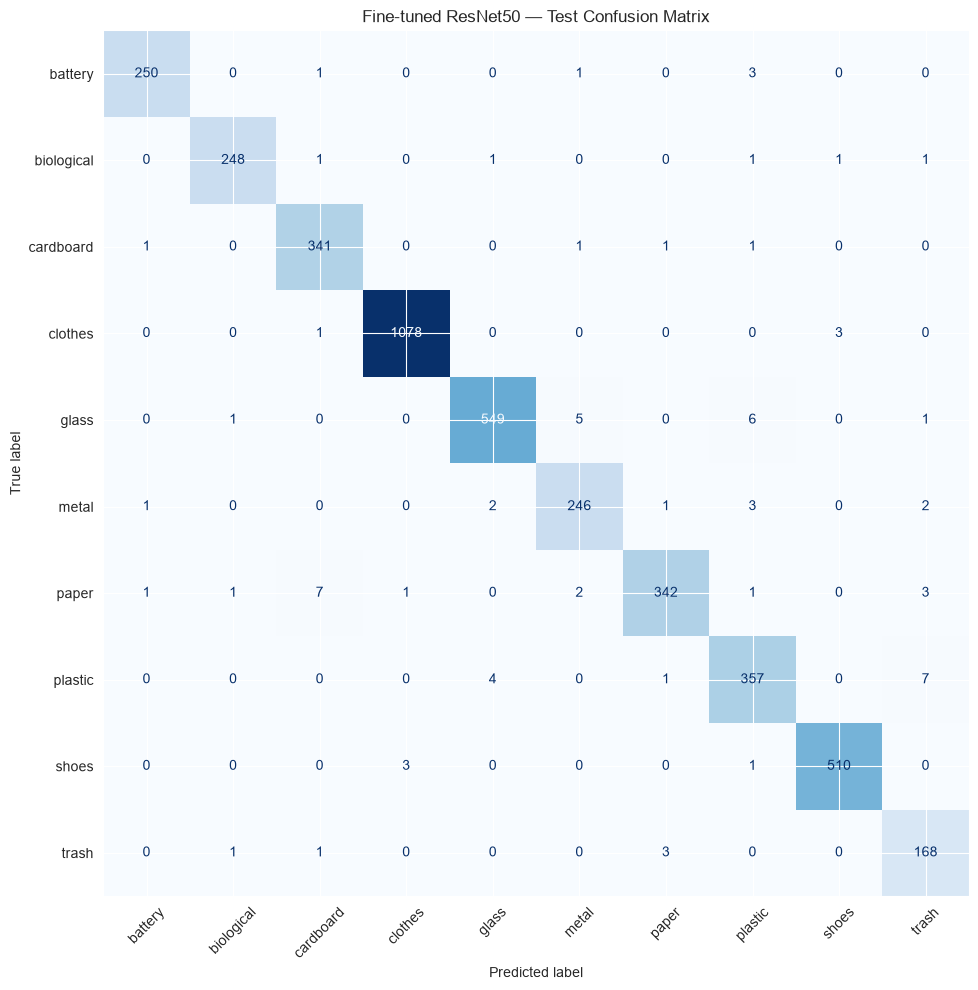

In [42]:
cm_test = confusion_matrix(
    all_test_labels,
    all_test_predictions,
    labels=list(range(len(class_labels)))
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=class_labels
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Fine-tuned ResNet50 — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [43]:
import torch
import torch.nn as nn
from torchvision import models

# Load the fine-tuned checkpoint
checkpoint = torch.load(
    "best_waste_resnet50_finetuned.pth",
    map_location=device,
    weights_only=False
)

# Reconstruct ResNet50
fine_resnet = models.resnet50(weights=None)

# Replace final classifier with 10 output classes
fine_resnet.fc = nn.Linear(
    fine_resnet.fc.in_features,
    len(checkpoint["class_to_idx"])
)

# Load trained weights
fine_resnet.load_state_dict(checkpoint["model_state_dict"])

fine_resnet = fine_resnet.to(device)
fine_resnet.eval()

# Use the exact class mapping saved with the checkpoint
class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Fine-tuned ResNet50 loaded successfully!")
print("Best epoch:", checkpoint["best_epoch"])
print("Validation Macro F1:", checkpoint["val_f1"])
print("Classes:", idx_to_class)


Fine-tuned ResNet50 loaded successfully!
Best epoch: 9
Validation Macro F1: 0.9787263149394485
Classes: {0: 'battery', 1: 'biological', 2: 'cardboard', 3: 'clothes', 4: 'glass', 5: 'metal', 6: 'paper', 7: 'plastic', 8: 'shoes', 9: 'trash'}


In [44]:
from tqdm.auto import tqdm

C:\Users\sohail\PycharmProjects\PythonProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [45]:
fine_resnet.eval()

trash_idx = class_to_idx["trash"]

misclassified_trash = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Analyzing test images"
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = fine_resnet(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = torch.max(
            probabilities,
            dim=1
        )

        for i in range(len(labels)):

            actual = labels[i].item()
            predicted = predictions[i].item()

            if actual == trash_idx and predicted != trash_idx:

                misclassified_trash.append({
                    "image": images[i].cpu(),
                    "actual": idx_to_class[actual],
                    "predicted": idx_to_class[predicted],
                    "confidence": confidences[i].item()
                })

print("\nTotal misclassified Trash images:",
      len(misclassified_trash))

error_df = pd.DataFrame([
    {
        "Actual": item["actual"],
        "Predicted": item["predicted"],
        "Confidence": round(item["confidence"], 4)
    }
    for item in misclassified_trash
])

display(error_df)


Analyzing test images: 100%|██████████| 131/131 [00:16<00:00,  8.10it/s]


Total misclassified Trash images: 5


,Actual,Predicted,Confidence
0,trash,paper,0.6548
1,trash,cardboard,0.6487
2,trash,paper,0.8527
3,trash,paper,0.9917
4,trash,biological,0.8398


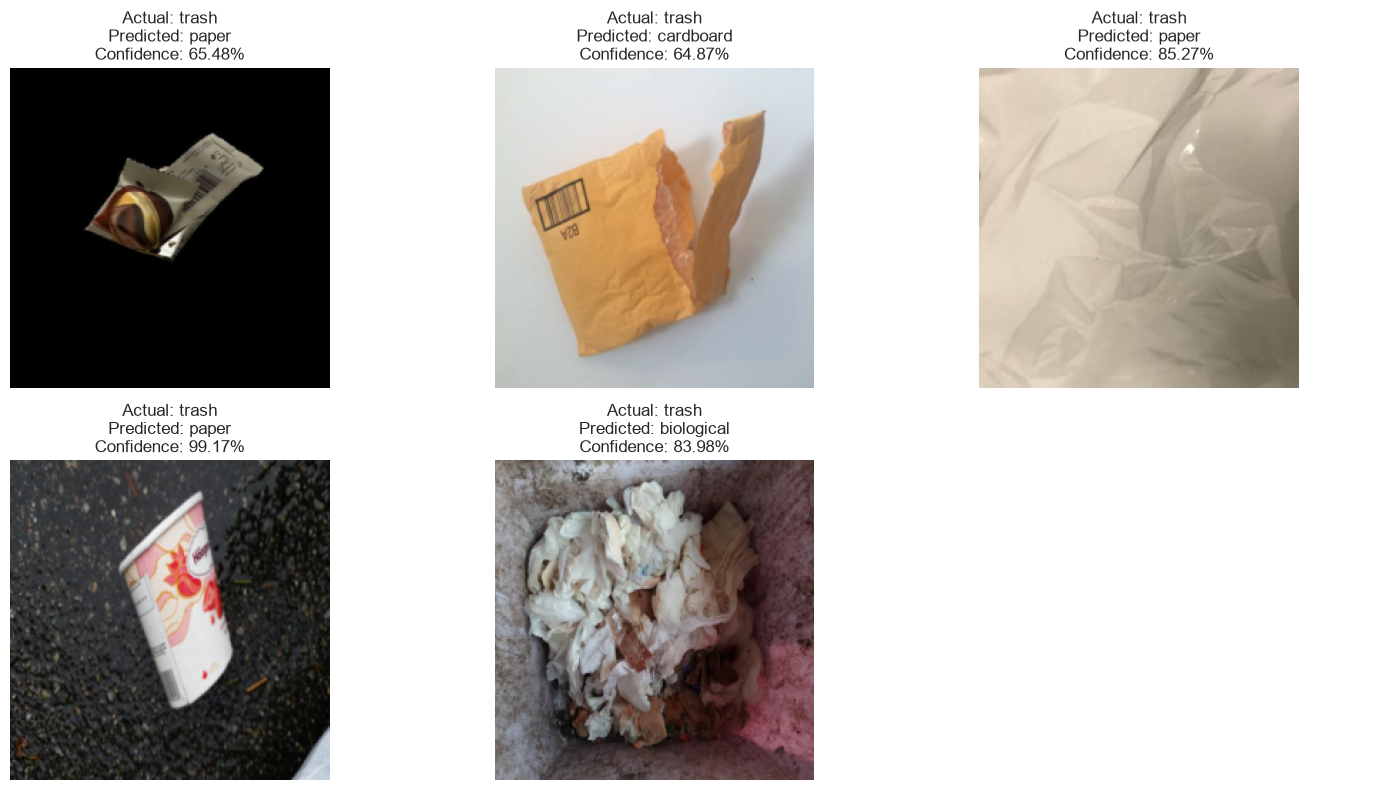

In [46]:
import matplotlib.pyplot as plt

num_images = len(misclassified_trash)

if num_images == 0:

    print("No misclassified Trash images found!")

else:

    cols = 3
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, rows * 4)
    )

    axes = axes.flatten()

    # Reverse ImageNet normalization
    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    for i, item in enumerate(misclassified_trash):

        img = item["image"]

        # Undo normalization
        img = img * std + mean
        img = img.clamp(0, 1)

        axes[i].imshow(img.permute(1, 2, 0))

        axes[i].set_title(
            f"Actual: {item['actual']}\n"
            f"Predicted: {item['predicted']}\n"
            f"Confidence: {item['confidence']:.2%}"
        )

        axes[i].axis("off")

    # Hide unused subplot spaces
    for i in range(num_images, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


In [47]:
import random

Trash training images: 804


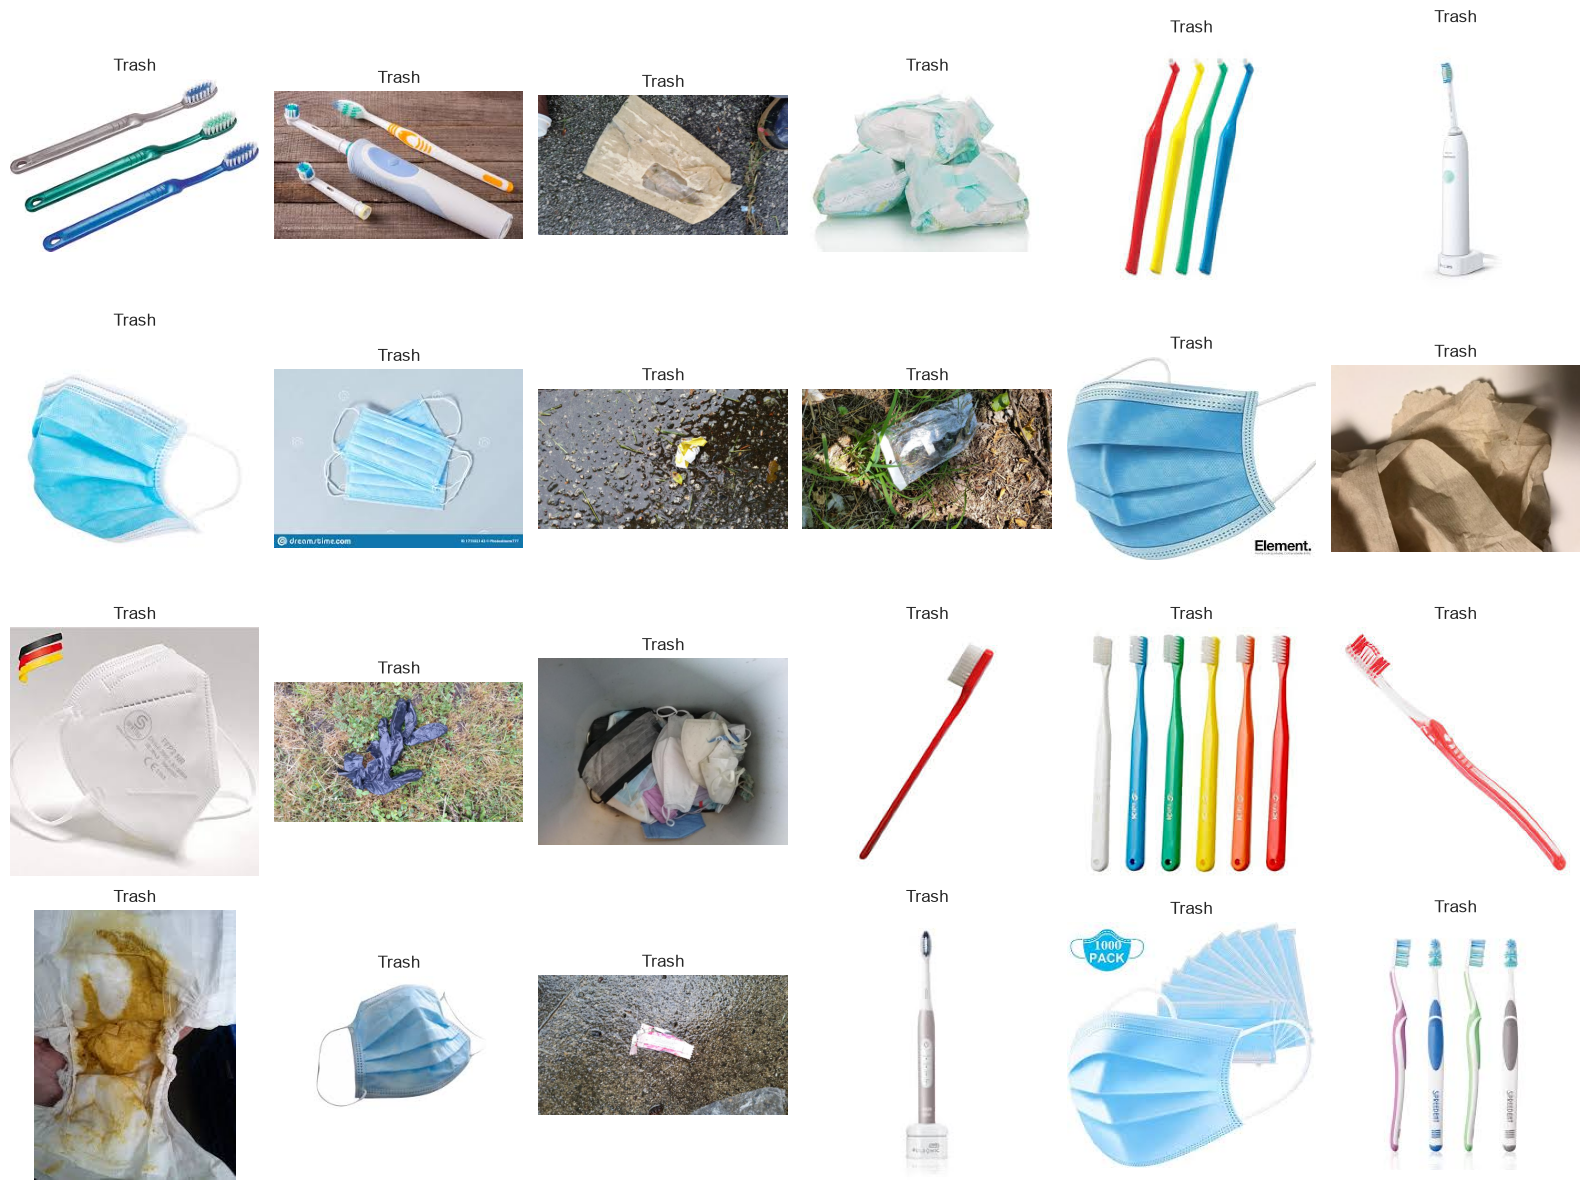

In [48]:
trash_train_df = train_df[
    train_df["label"].str.lower() == "trash"
].reset_index(drop=True)

print("Trash training images:", len(trash_train_df))

sample_df = trash_train_df.sample(
    n=min(24, len(trash_train_df)),
    random_state=42
)

fig, axes = plt.subplots(4, 6, figsize=(16, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_df.iterrows()):

    img = Image.open(row["image_path"]).convert("RGB")

    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title("Trash")

plt.tight_layout()
plt.show()


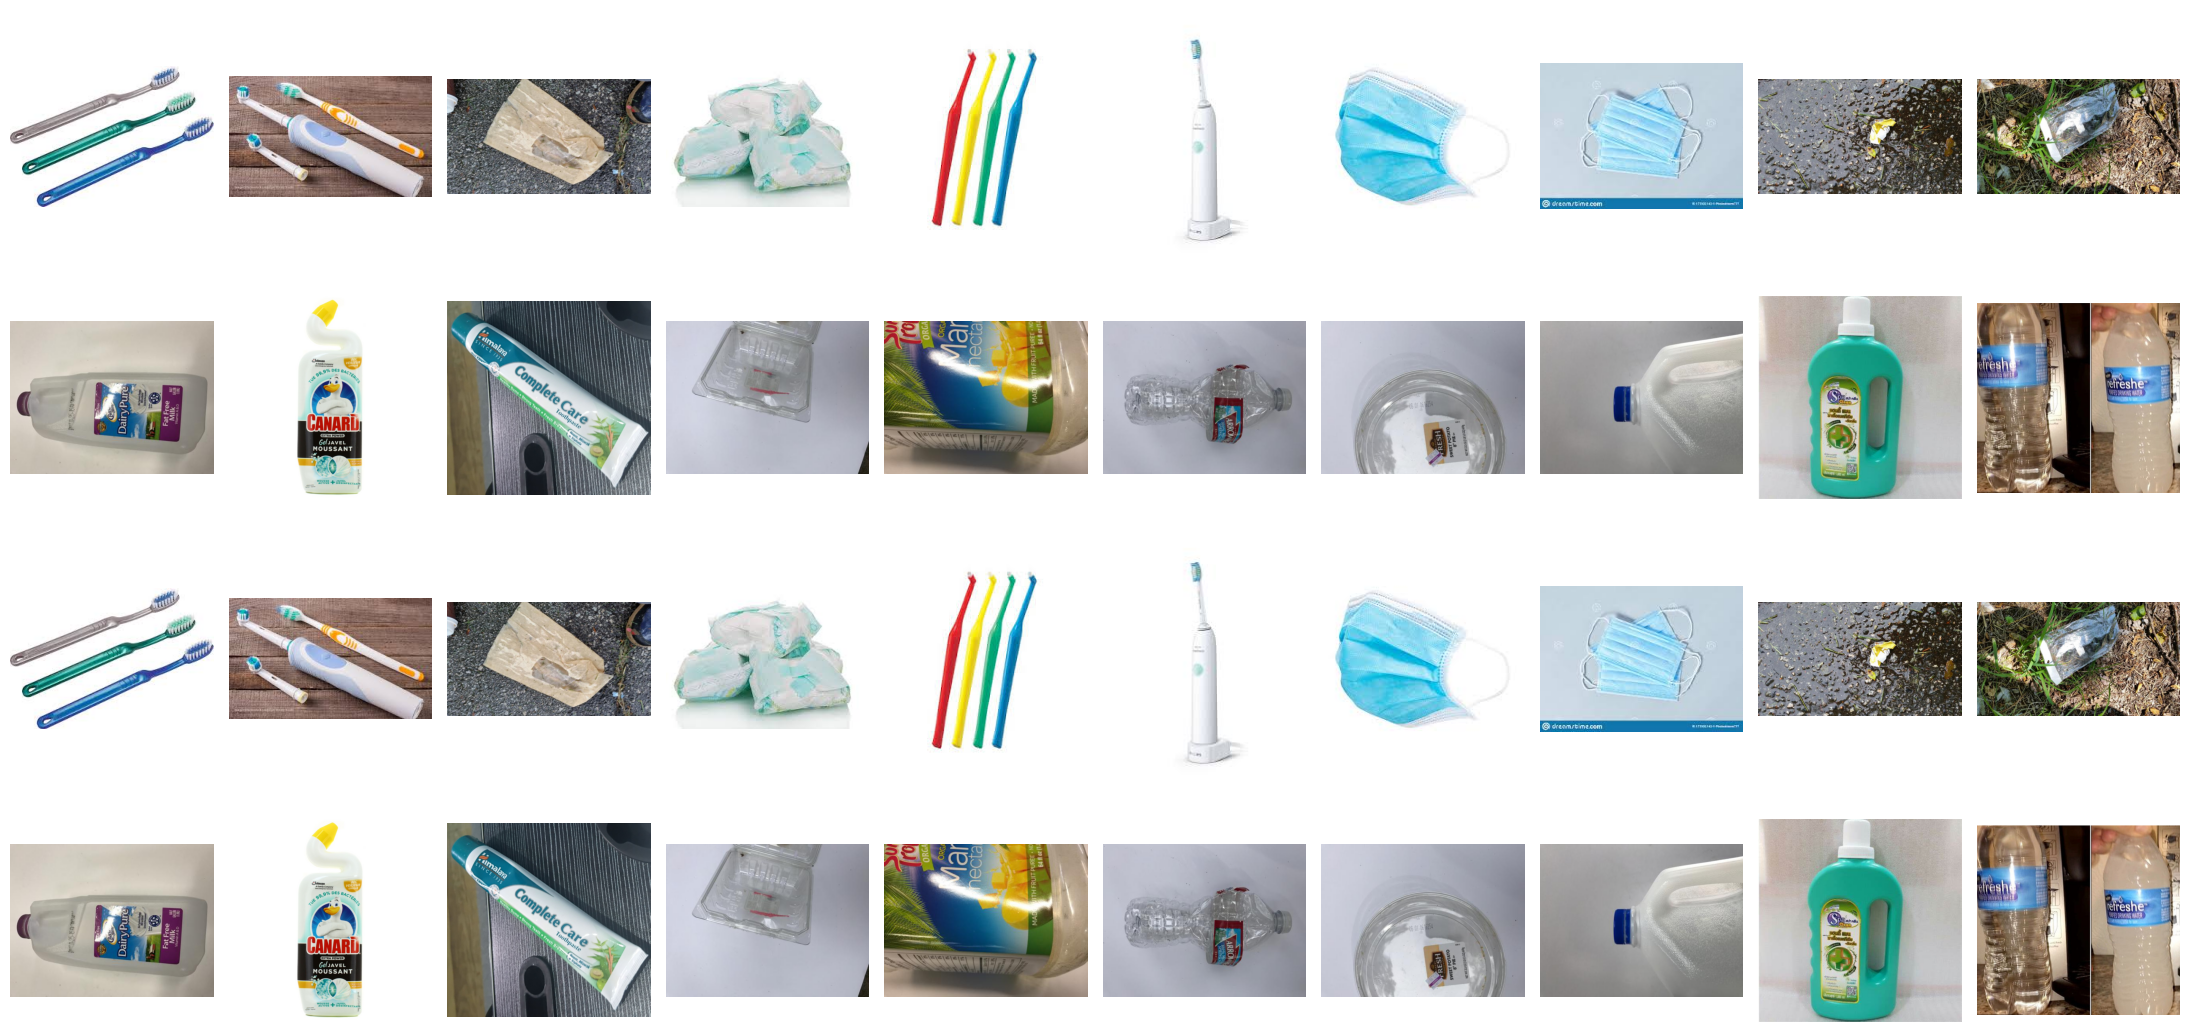

In [49]:
trash_samples = train_df[
    train_df["label"].str.lower() == "trash"
].sample(n=20, random_state=42)

plastic_samples = train_df[
    train_df["label"].str.lower() == "plastic"
].sample(n=20, random_state=42)

fig, axes = plt.subplots(4, 10, figsize=(22, 11))

for row in range(2):

    samples = trash_samples if row == 0 else plastic_samples
    class_name = "TRASH" if row == 0 else "PLASTIC"

    for col in range(10):

        img_path = samples.iloc[col]["image_path"]
        img = Image.open(img_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        class_name,
        fontsize=14,
        fontweight="bold"
    )

    samples = trash_samples if row == 0 else plastic_samples

    for col in range(10, 20):

        img_path = samples.iloc[col - 10]["image_path"]
        img = Image.open(img_path).convert("RGB")

        axes[row + 2, col - 10].imshow(img)
        axes[row + 2, col - 10].axis("off")

    axes[row + 2, 0].set_ylabel(
        class_name,
        fontsize=14,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


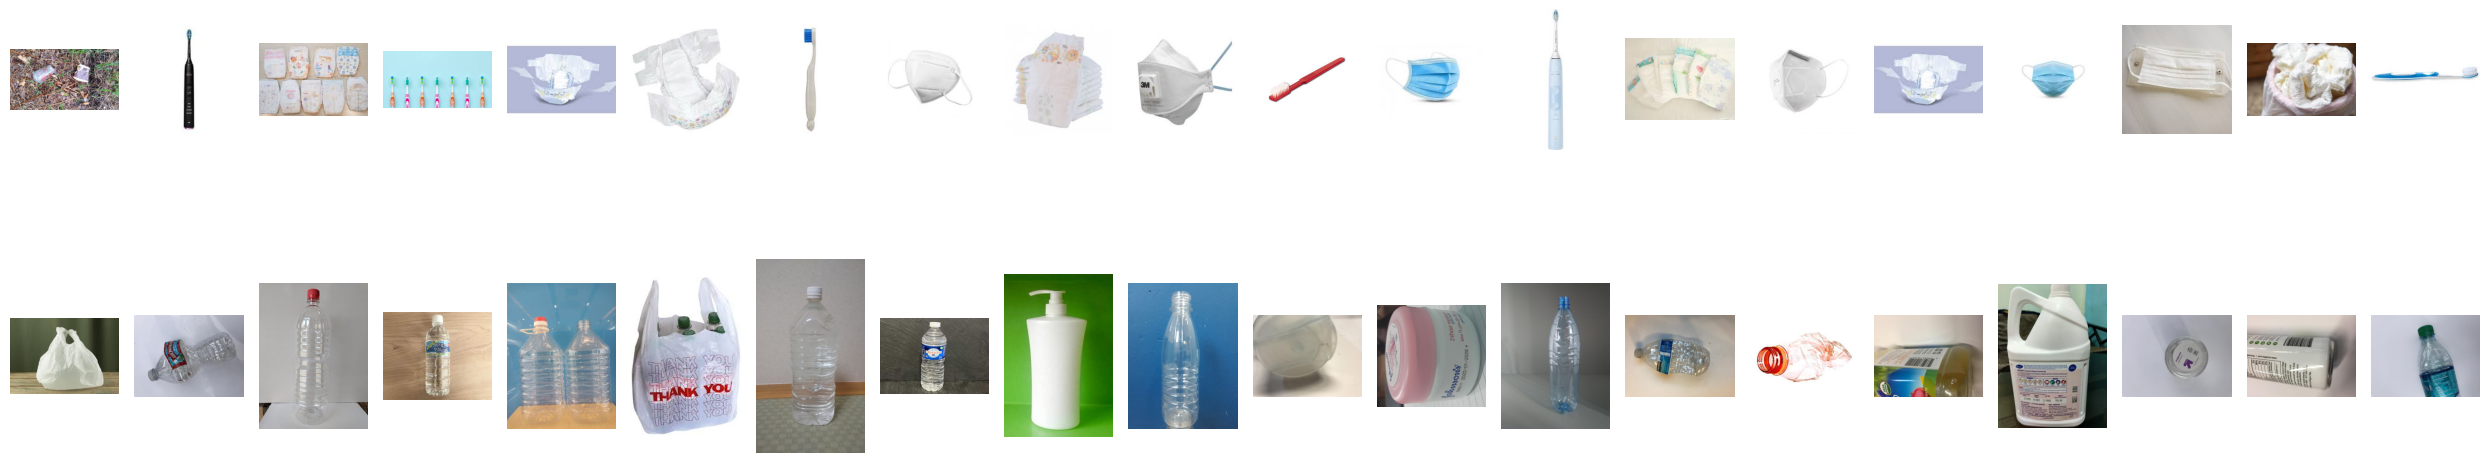

In [50]:
trash_samples = train_df[
    train_df["label"].str.lower() == "trash"
].sample(n=20, random_state=100)

plastic_samples = train_df[
    train_df["label"].str.lower() == "plastic"
].sample(n=20, random_state=100)

fig, axes = plt.subplots(2, 20, figsize=(25, 7))

for col in range(20):

    # Trash images
    img = Image.open(
        trash_samples.iloc[col]["image_path"]
    ).convert("RGB")

    axes[0, col].imshow(img)
    axes[0, col].axis("off")

    # Plastic images
    img = Image.open(
        plastic_samples.iloc[col]["image_path"]
    ).convert("RGB")

    axes[1, col].imshow(img)
    axes[1, col].axis("off")

axes[0, 0].set_ylabel(
    "TRASH", fontsize=13, fontweight="bold"
)

axes[1, 0].set_ylabel(
    "PLASTIC", fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.show()


In [51]:
from collections import Counter

In [52]:
# Count training samples per class
class_counts = Counter(train_df["label"])

# Ensure weights follow the exact class index order
counts = torch.tensor(
    [
        class_counts[class_name]
        for class_name, idx in sorted(
            class_to_idx.items(),
            key=lambda item: item[1]
        )
    ],
    dtype=torch.float32
)

# Inverse-frequency class weights
class_weights = 1.0 / counts

# Normalize weights so their mean is 1
class_weights = class_weights / class_weights.mean()

class_weights = class_weights.to(device)

print("Class weights:")

for class_name, idx in sorted(
    class_to_idx.items(),
    key=lambda item: item[1]
):
    print(
        f"{class_name:25s}: "
        f"{class_weights[idx].item():.4f} "
        f"(training images: {counts[idx].item():.0f})"
    )

Class weights:
battery                  : 1.2783 (training images: 1191)
biological               : 1.2913 (training images: 1179)
cardboard                : 0.9444 (training images: 1612)
clothes                  : 0.3014 (training images: 5052)
glass                    : 0.5804 (training images: 2623)
metal                    : 1.2804 (training images: 1189)
paper                    : 0.9116 (training images: 1670)
plastic                  : 0.8836 (training images: 1723)
shoes                    : 0.6349 (training images: 2398)
trash                    : 1.8936 (training images: 804)


In [53]:
checkpoint = torch.load(
    "best_waste_resnet50_finetuned.pth",
    map_location=device,
    weights_only=False
)

weighted_resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

weighted_resnet.fc = nn.Linear(
    weighted_resnet.fc.in_features,
    len(classes)
)

weighted_resnet.load_state_dict(
    checkpoint["model_state_dict"]
)

<All keys matched successfully>

In [54]:
for param in weighted_resnet.parameters():
    param.requires_grad = False

for param in weighted_resnet.layer4.parameters():
    param.requires_grad = True

for param in weighted_resnet.fc.parameters():
    param.requires_grad = True

weighted_resnet = weighted_resnet.to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [55]:
optimizer = optim.Adam([
    {
        "params": weighted_resnet.layer4.parameters(),
        "lr": 0.0001
    },
    {
        "params": weighted_resnet.fc.parameters(),
        "lr": 0.0005
    }
])

print("Class-weighted ResNet50 initialized!")
print("Trainable parameters:",
      sum(p.numel() for p in weighted_resnet.parameters()
          if p.requires_grad))
print("Loss function:", criterion)

Class-weighted ResNet50 initialized!
Trainable parameters: 14985226
Loss function: CrossEntropyLoss()


In [56]:
EPOCHS = 50
PATIENCE = 5

best_val_f1 = -1
best_epoch = 0
patience_counter = 0

weighted_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        weighted_resnet,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_f1 = evaluate_model(
        weighted_resnet,
        val_loader,
        criterion,
        device
    )

    weighted_history["train_loss"].append(train_loss)
    weighted_history["train_acc"].append(train_acc)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["val_acc"].append(val_acc)
    weighted_history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc*100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc*100:.2f}% "
        f"| Val Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            {
                "model_state_dict": weighted_resnet.state_dict(),
                "class_to_idx": class_to_idx,
                "best_epoch": best_epoch,
                "val_f1": best_val_f1
            },
            "best_waste_resnet50_weighted.pth"
        )

        print("  -> Best model saved!")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nClass-weighted training completed!")
print("Best epoch:", best_epoch)
print(f"Best validation Macro F1: {best_val_f1:.4f}")

Epoch [1/50] | Train Loss: 0.0742 | Train Acc: 97.79% | Val Loss: 0.1035 | Val Acc: 97.96% | Val Macro F1: 0.9735
  -> Best model saved!
Epoch [2/50] | Train Loss: 0.0833 | Train Acc: 97.45% | Val Loss: 0.0879 | Val Acc: 98.32% | Val Macro F1: 0.9789
  -> Best model saved!
Epoch [3/50] | Train Loss: 0.0695 | Train Acc: 98.06% | Val Loss: 0.0928 | Val Acc: 98.18% | Val Macro F1: 0.9783
Epoch [4/50] | Train Loss: 0.0694 | Train Acc: 97.84% | Val Loss: 0.0941 | Val Acc: 98.20% | Val Macro F1: 0.9778
Epoch [5/50] | Train Loss: 0.0700 | Train Acc: 97.98% | Val Loss: 0.1118 | Val Acc: 98.10% | Val Macro F1: 0.9755
Epoch [6/50] | Train Loss: 0.0691 | Train Acc: 97.90% | Val Loss: 0.1054 | Val Acc: 97.91% | Val Macro F1: 0.9739
Epoch [7/50] | Train Loss: 0.0638 | Train Acc: 98.00% | Val Loss: 0.0937 | Val Acc: 98.32% | Val Macro F1: 0.9801
  -> Best model saved!
Epoch [8/50] | Train Loss: 0.0627 | Train Acc: 98.07% | Val Loss: 0.1003 | Val Acc: 98.32% | Val Macro F1: 0.9783
Epoch [9/50] | Trai

In [57]:
import seaborn as sns

CLASS-WEIGHTED RESNET50 - VALIDATION RESULTS
Accuracy:  0.9832
Macro Precision: 0.9796
Macro Recall:    0.9807
Macro F1:        0.9801

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     battery     0.9922    0.9961    0.9941       255
  biological     0.9921    0.9960    0.9941       252
   cardboard     0.9740    0.9768    0.9754       345
     clothes     0.9963    0.9908    0.9935      1083
       glass     0.9893    0.9840    0.9866       562
       metal     0.9802    0.9725    0.9764       255
       paper     0.9636    0.9609    0.9622       358
     plastic     0.9677    0.9703    0.9690       370
       shoes     0.9808    0.9942    0.9874       514
       trash     0.9595    0.9651    0.9623       172

    accuracy                         0.9832      4166
   macro avg     0.9796    0.9807    0.9801      4166
weighted avg     0.9832    0.9832    0.9832      4166



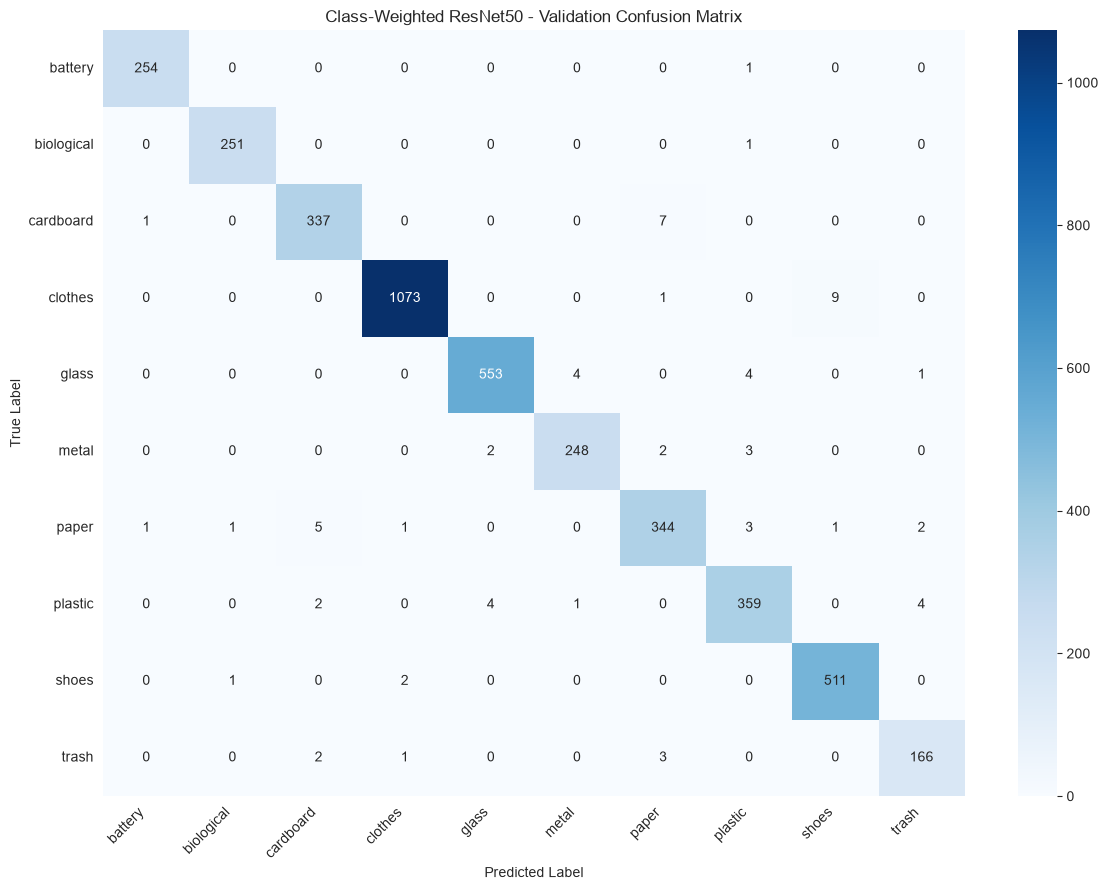

In [58]:
checkpoint = torch.load(
    "best_waste_resnet50_weighted.pth",
    map_location=device,
    weights_only=False
)

weighted_eval_model = models.resnet50(
    weights=None
)

weighted_eval_model.fc = nn.Linear(
    weighted_eval_model.fc.in_features,
    len(classes)
)

weighted_eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)

weighted_eval_model = weighted_eval_model.to(device)
weighted_eval_model.eval()

class_names = [
    name for name, idx in sorted(
        class_to_idx.items(),
        key=lambda item: item[1]
    )
]

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = weighted_eval_model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Overall metrics
print("CLASS-WEIGHTED RESNET50 - VALIDATION RESULTS")
print("=" * 55)

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro Precision: {precision_score(y_true, y_pred, average='macro'):.4f}")
print(f"Macro Recall:    {recall_score(y_true, y_pred, average='macro'):.4f}")
print(f"Macro F1:        {f1_score(y_true, y_pred, average='macro'):.4f}")

# Classification report
print("\nCLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Class-Weighted ResNet50 - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

In [60]:
# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint
checkpoint_path = "best_waste_resnet50_weighted.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Get class mapping saved during training
class_to_idx = checkpoint["class_to_idx"]

# Reverse mapping: index -> class name
idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

# Number of classes
num_classes = len(class_to_idx)

# Create ResNet50 architecture
model = models.resnet50(weights=None)

# Replace classification layer
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

# IMPORTANT: Load the actual model weights
model.load_state_dict(checkpoint["model_state_dict"])

# Move model to GPU/CPU
model = model.to(device)

# Evaluation mode
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Number of classes:", num_classes)
print("Class mapping:", idx_to_class)
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation F1:", checkpoint["val_f1"])

Model loaded successfully!
Device: cuda
Number of classes: 10
Class mapping: {0: 'battery', 1: 'biological', 2: 'cardboard', 3: 'clothes', 4: 'glass', 5: 'metal', 6: 'paper', 7: 'plastic', 8: 'shoes', 9: 'trash'}
Best epoch: 7
Best validation F1: 0.980105917981841


In [61]:
# Image preprocessing
predict_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def predict_waste(image_path):

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Apply preprocessing
    image = predict_transform(image)

    # Add batch dimension
    image = image.unsqueeze(0)

    # Move image to device
    image = image.to(device)

    # Make prediction
    with torch.no_grad():

        outputs = model(image)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted_index = torch.max(
            probabilities, dim=1
        )

    # Convert predicted index to class name
    predicted_class = idx_to_class[predicted_index.item()]

    confidence = confidence.item() * 100

    return predicted_class, confidence

In [62]:
image_path = r"C:\Users\sohail\PycharmProjects\PythonProject\test_images\cardboard.jpeg"

predicted_class, confidence = predict_waste(image_path)

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Predicted class: cardboard
Confidence: 100.00%


In [63]:
image_path = r"C:\Users\sohail\PycharmProjects\PythonProject\test_images\plastic.jpeg"

predicted_class, confidence = predict_waste(image_path)

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Predicted class: plastic
Confidence: 100.00%


In [64]:
image_path = r"C:\Users\sohail\PycharmProjects\PythonProject\test_images\metal.jpeg"

predicted_class, confidence = predict_waste(image_path)

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Predicted class: metal
Confidence: 93.80%
